In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
from scipy import constants
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

In [3]:
from labmate.acquisition_notebook import AcquisitionAnalysisManager

In [4]:
from utils.plot_style import set_plot_style 
set_plot_style()

In [5]:
# Some Jupyter instance will not be launched in the root folder of the repository, so we need to change the working directory to access the data and utils modules. We check the current working directory and move up one level if needed.
# Run only once! (if necessary)
print(os.getcwd())
os.chdir('..')
print(os.getcwd())

C:\Users\wilan\PycharmProjects\PANDAManager\plot
C:\Users\wilan\PycharmProjects\PANDAManager


In [5]:
smooth_N = 25

def smooth(y, N):
    kernel = np.ones(N) / N
    return np.convolve(y, kernel, mode="same")

In [6]:
def lorentzian(x, A, x0, gamma, C):
    return A * (0.5 * gamma)**2 / ((x - x0)**2 + (0.5 * gamma)**2) + C

In [7]:
c = constants.c  # speed of light in m/s

# Birefringence plot

## Load Data

In [14]:
# Folder
path_folder_data = r"./data/oscilloscope/oscilloscope_trace/2026-10-01_shg_cavity_empty_001"
folder_data_files = os.listdir(path_folder_data)
print(folder_data_files)
# Run names
name_exp = 'oscilloscope_trace_shg_cavity_empty'
# List all files in the folder
folder_data_files = os.listdir(path_folder_data + '/' + name_exp)
print(folder_data_files)

['oscilloscope_trace', 'oscilloscope_trace_shg_cavity_empty', 'temp.json']
['2026_10_01__10_41_47__oscilloscope_trace_shg_cavity_empty.h5']


In [15]:
# Choose file
# name = "2026_05_12__08_05_23__oscilloscope_trace.h5"
# name = "2026_05_12__09_00_53__oscilloscope_trace.h5"
name = "2026_10_01__10_41_47__oscilloscope_trace_shg_cavity_empty.h5"

full_path = os.path.join(path_folder_data, name_exp, name)
print(full_path)

# Init acquisition analysis manager
aqm = AcquisitionAnalysisManager(full_path)
aqm.analysis_cell(filename=full_path)
print(aqm.data)

./data/oscilloscope/oscilloscope_trace/2026-10-01_shg_cavity_empty_001\oscilloscope_trace_shg_cavity_empty\2026_10_01__10_41_47__oscilloscope_trace_shg_cavity_empty.h5


INFO:2026_10_01__10_41_47__oscilloscope_trace_shg_cavity_empty


AnalysisData (rw) (not saved): 
 {
    "CH1_pt_off" (r): "0.000e+00 (type : float64)",
    "CH1_x" (r): "shape: (125000,) (type: ndarray)",
    "CH1_xincr" (r): "1.600e-06 (type : float64)",
    "CH1_xzero" (r): "-0.100 (type : float64)",
    "CH1_y" (r): "shape: (125000,) (type: ndarray)",
    "CH1_y_raw" (r): "shape: (125000,) (type: ndarray)",
    "CH1_ymult" (r): "2.000e-02 (type : float64)",
    "CH1_yoff" (r): "-44.000 (type : float64)",
    "CH1_yzero" (r): "0.000e+00 (type : float64)",
    "CH2_pt_off" (r): "0.000e+00 (type : float64)",
    "CH2_x" (r): "shape: (125000,) (type: ndarray)",
    "CH2_xincr" (r): "1.600e-06 (type : float64)",
    "CH2_xzero" (r): "-0.100 (type : float64)",
    "CH2_y" (r): "shape: (125000,) (type: ndarray)",
    "CH2_y_raw" (r): "shape: (125000,) (type: ndarray)",
    "CH2_ymult" (r): "4.000e-04 (type : float64)",
    "CH2_yoff" (r): "-100.000 (type : float64)",
    "CH2_yzero" (r): "0.000e+00 (type : float64)",
    "CH3_pt_off" (r): "0.000e+00 (ty

In [16]:
x_list = []
y_list = []
ch_list = []
file_list = []

aqm = AcquisitionAnalysisManager(os.path.join(path_folder_data, name_exp))

full_path = os.path.join(path_folder_data, name_exp, name)
aqm.analysis_cell(filename=full_path)

data = aqm.data

# find channels present in this file
channels = []
for ch in ["CH1", "CH2", "CH3", "CH4"]:
    if f"{ch}_x" in data and f"{ch}_y" in data:
        channels.append(ch)

for ch in channels:
    x_list.append(data[f"{ch}_x"])
    y_list.append(data[f"{ch}_y"])
    ch_list.append(ch)
    file_list.append(name)

    print(f"Loaded {name} / {ch}")

INFO:2026_10_01__10_41_47__oscilloscope_trace_shg_cavity_empty


Loaded 2026_10_01__10_41_47__oscilloscope_trace_shg_cavity_empty.h5 / CH1
Loaded 2026_10_01__10_41_47__oscilloscope_trace_shg_cavity_empty.h5 / CH2
Loaded 2026_10_01__10_41_47__oscilloscope_trace_shg_cavity_empty.h5 / CH3


## Plot Data

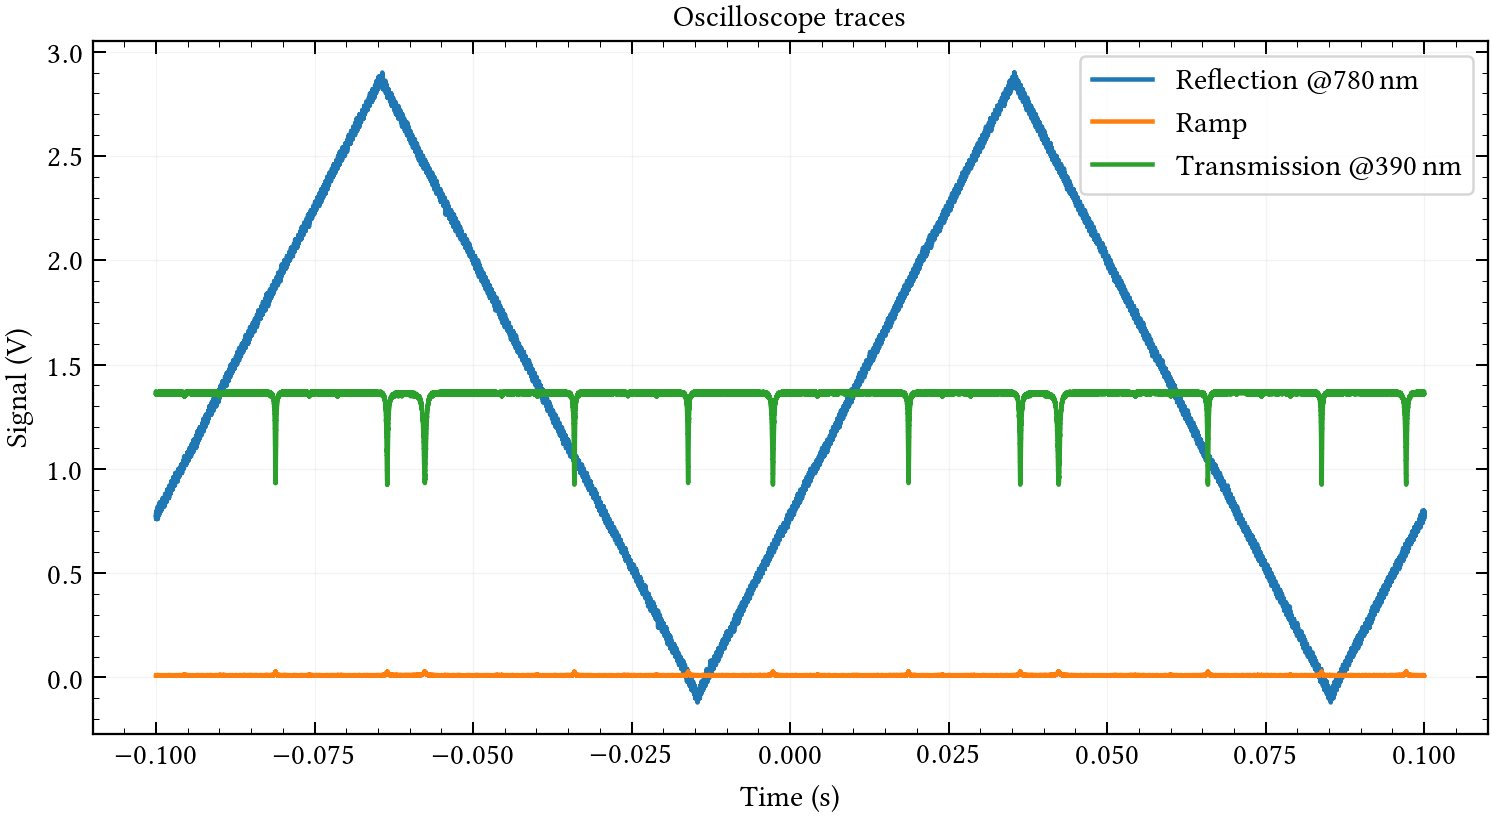

In [17]:
# custom labels
label_map = {
    "CH1": r"Reflection $@780\,\mathrm{nm}$",
    "CH2": r"Ramp",
    "CH3": r"Transmission $@390\,\mathrm{nm}$",
}

# Plot
set_plot_style()
fig, ax = plt.subplots(figsize=(10,5))

for x, y, ch in zip(x_list, y_list, ch_list):

    # fallback to channel name if not defined
    label = label_map.get(ch, ch)

    ax.plot(x, y, label=label)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Signal (V)")
ax.set_title("Oscilloscope traces")
ax.grid()

legend = ax.legend(loc="upper right", frameon=True)
legend.get_frame().set_facecolor('white')

plt.show()

## Leak study of lock beam

INFO:2026_05_12__09_18_57__oscilloscope_trace


INFO:2026_05_12__09_20_03__oscilloscope_trace


INFO:2026_05_12__09_41_35__oscilloscope_trace


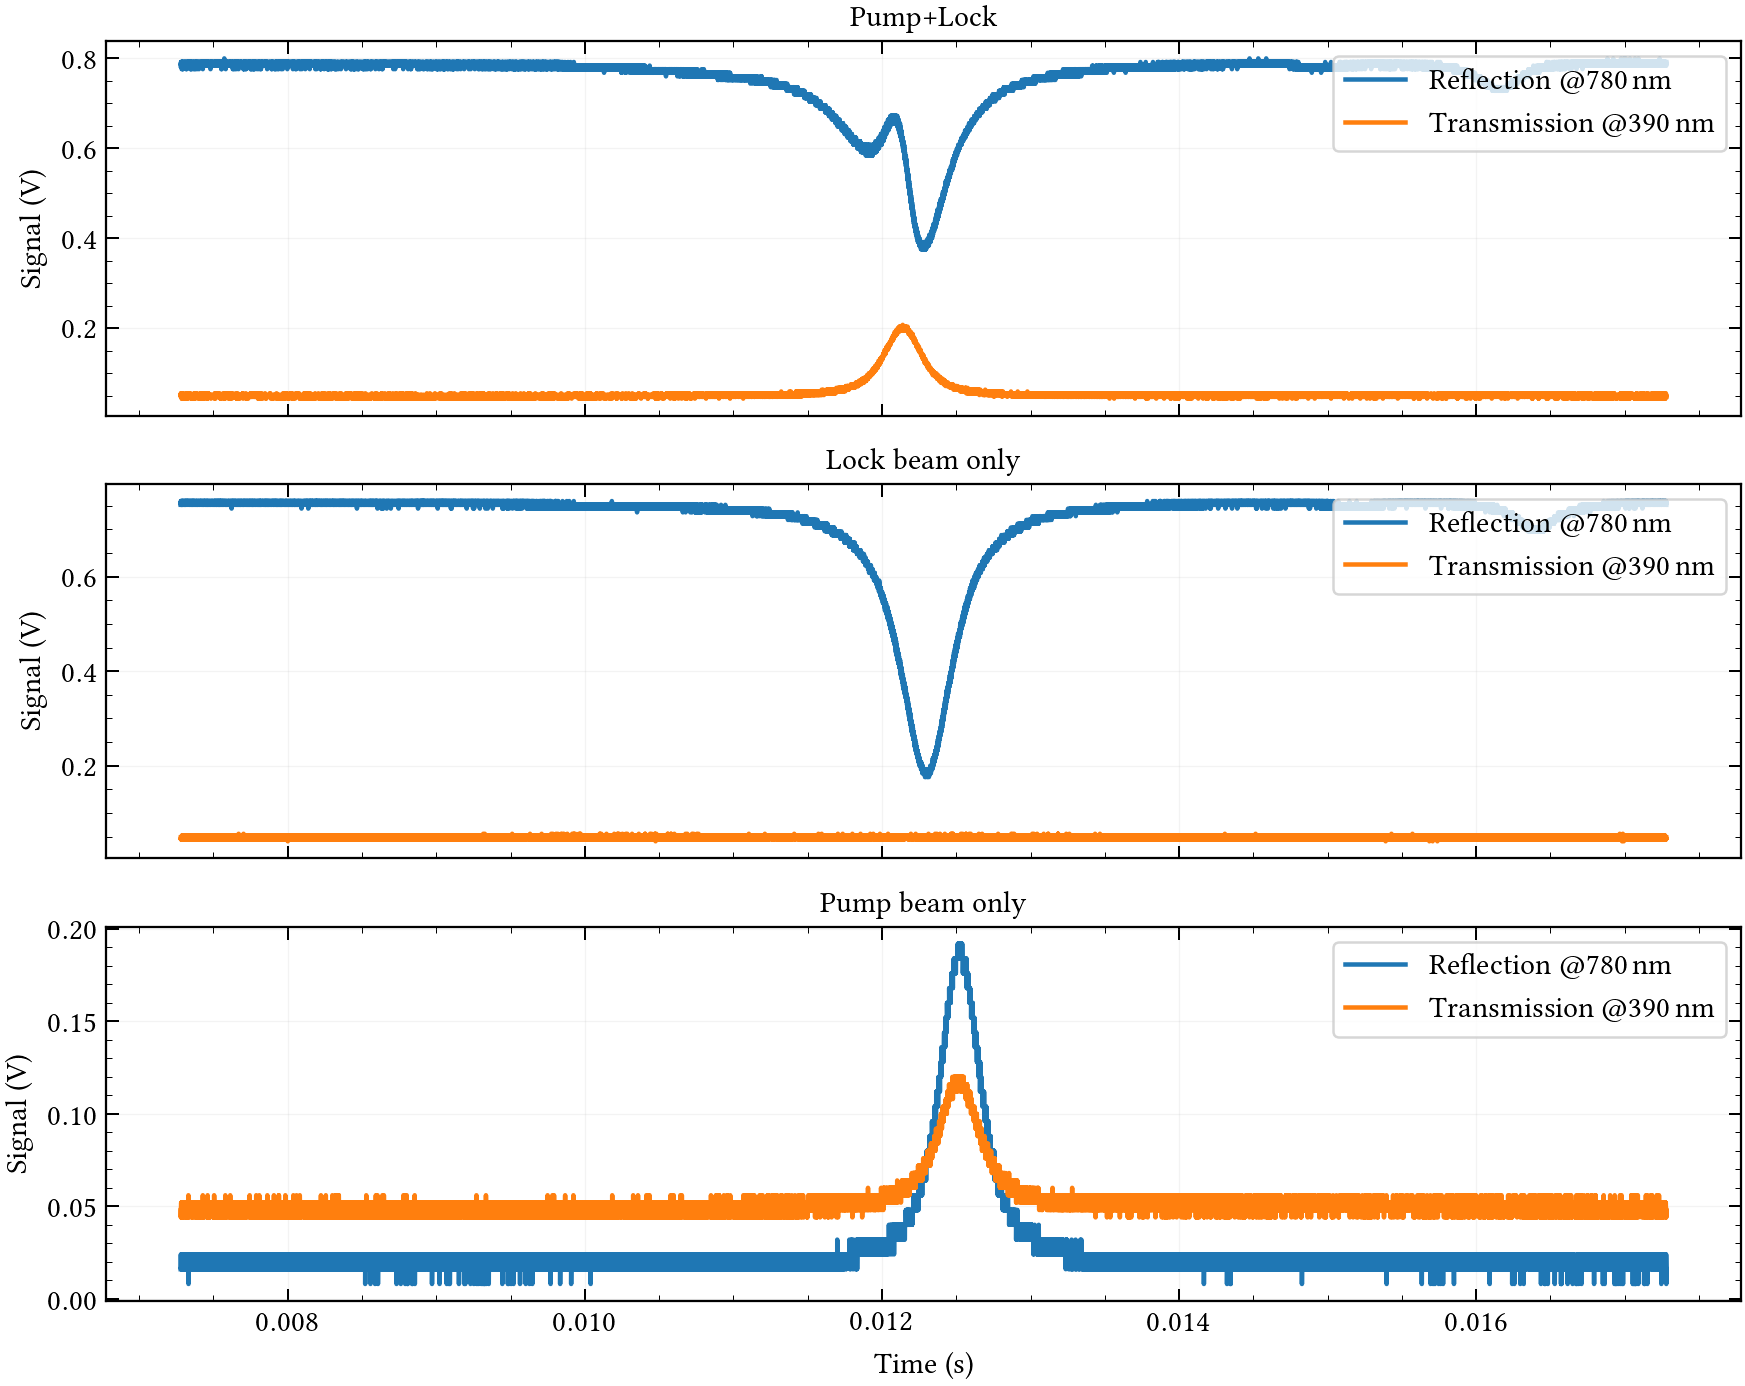

In [10]:
# List all files in the folder
path_folder_data = r"./data/oscilloscope/scope_acq_2026_05_12__07_45_12/"

# name1 = "2026_05_12__09_09_43__oscilloscope_trace.h5"
# name2 = "2026_05_12__09_10_28__oscilloscope_trace.h5"

name1 = "2026_05_12__09_18_57__oscilloscope_trace.h5"
name2 = "2026_05_12__09_20_03__oscilloscope_trace.h5"
name3 = "2026_05_12__09_41_35__oscilloscope_trace.h5"

# name1 = "2026_05_12__09_48_41__oscilloscope_trace.h5"
# name2 = "2026_05_12__09_48_07__oscilloscope_trace.h5"
# name3 = "2026_05_12__09_49_16__oscilloscope_trace.h5"

# subplot titles
subplot_titles = [
    "Pump+Lock",
    "Lock beam only",
    "Pump beam only",
]

name_exp = 'oscilloscope_trace'

aqm = AcquisitionAnalysisManager(
    os.path.join(path_folder_data, name_exp)
)

# files to compare
file_names = [name1, name2, name3]

# custom labels
label_map = {
    "CH1": r"Reflection $@780\,\mathrm{nm}$",
    "CH2": r"Ramp",
    "CH3": r"Transmission $@390\,\mathrm{nm}$",
}

# Plot
set_plot_style()

fig, axs = plt.subplots(
    3, 1,
    figsize=(10, 8),
    sharex=True
)

for ax, name, subplot_title  in zip(axs, file_names, subplot_titles):

    full_path = os.path.join(
        path_folder_data,
        name_exp,
        name
    )

    aqm.analysis_cell(filename=full_path)
    data = aqm.data

    # find channels present in this file
    channels = []
    for ch in ["CH1", "CH2", "CH3", "CH4"]:
        if f"{ch}_x" in data and f"{ch}_y" in data:
            channels.append(ch)

    for ch in channels:

        x = data[f"{ch}_x"]
        y = data[f"{ch}_y"]

        # comment ramp out but keep code
        if ch == "CH2":
            continue

        # fallback to channel name if not defined
        label = label_map.get(ch, ch)

        ax.plot(x, y, label=label)

    ax.set_ylabel("Signal (V)")
    ax.set_title(subplot_title)
    ax.grid()

    legend = ax.legend(loc="upper right", frameon=True)
    legend.get_frame().set_facecolor('white')

axs[-1].set_xlabel("Time (s)")

plt.tight_layout()
plt.show()

INFO:2026_05_12__09_20_03__oscilloscope_trace


INFO:2026_05_12__09_41_35__oscilloscope_trace


INFO:2026_05_12__09_18_57__oscilloscope_trace


Lock only: 37501 points
Pump only: 37500 points
Pump + Lock: 37501 points


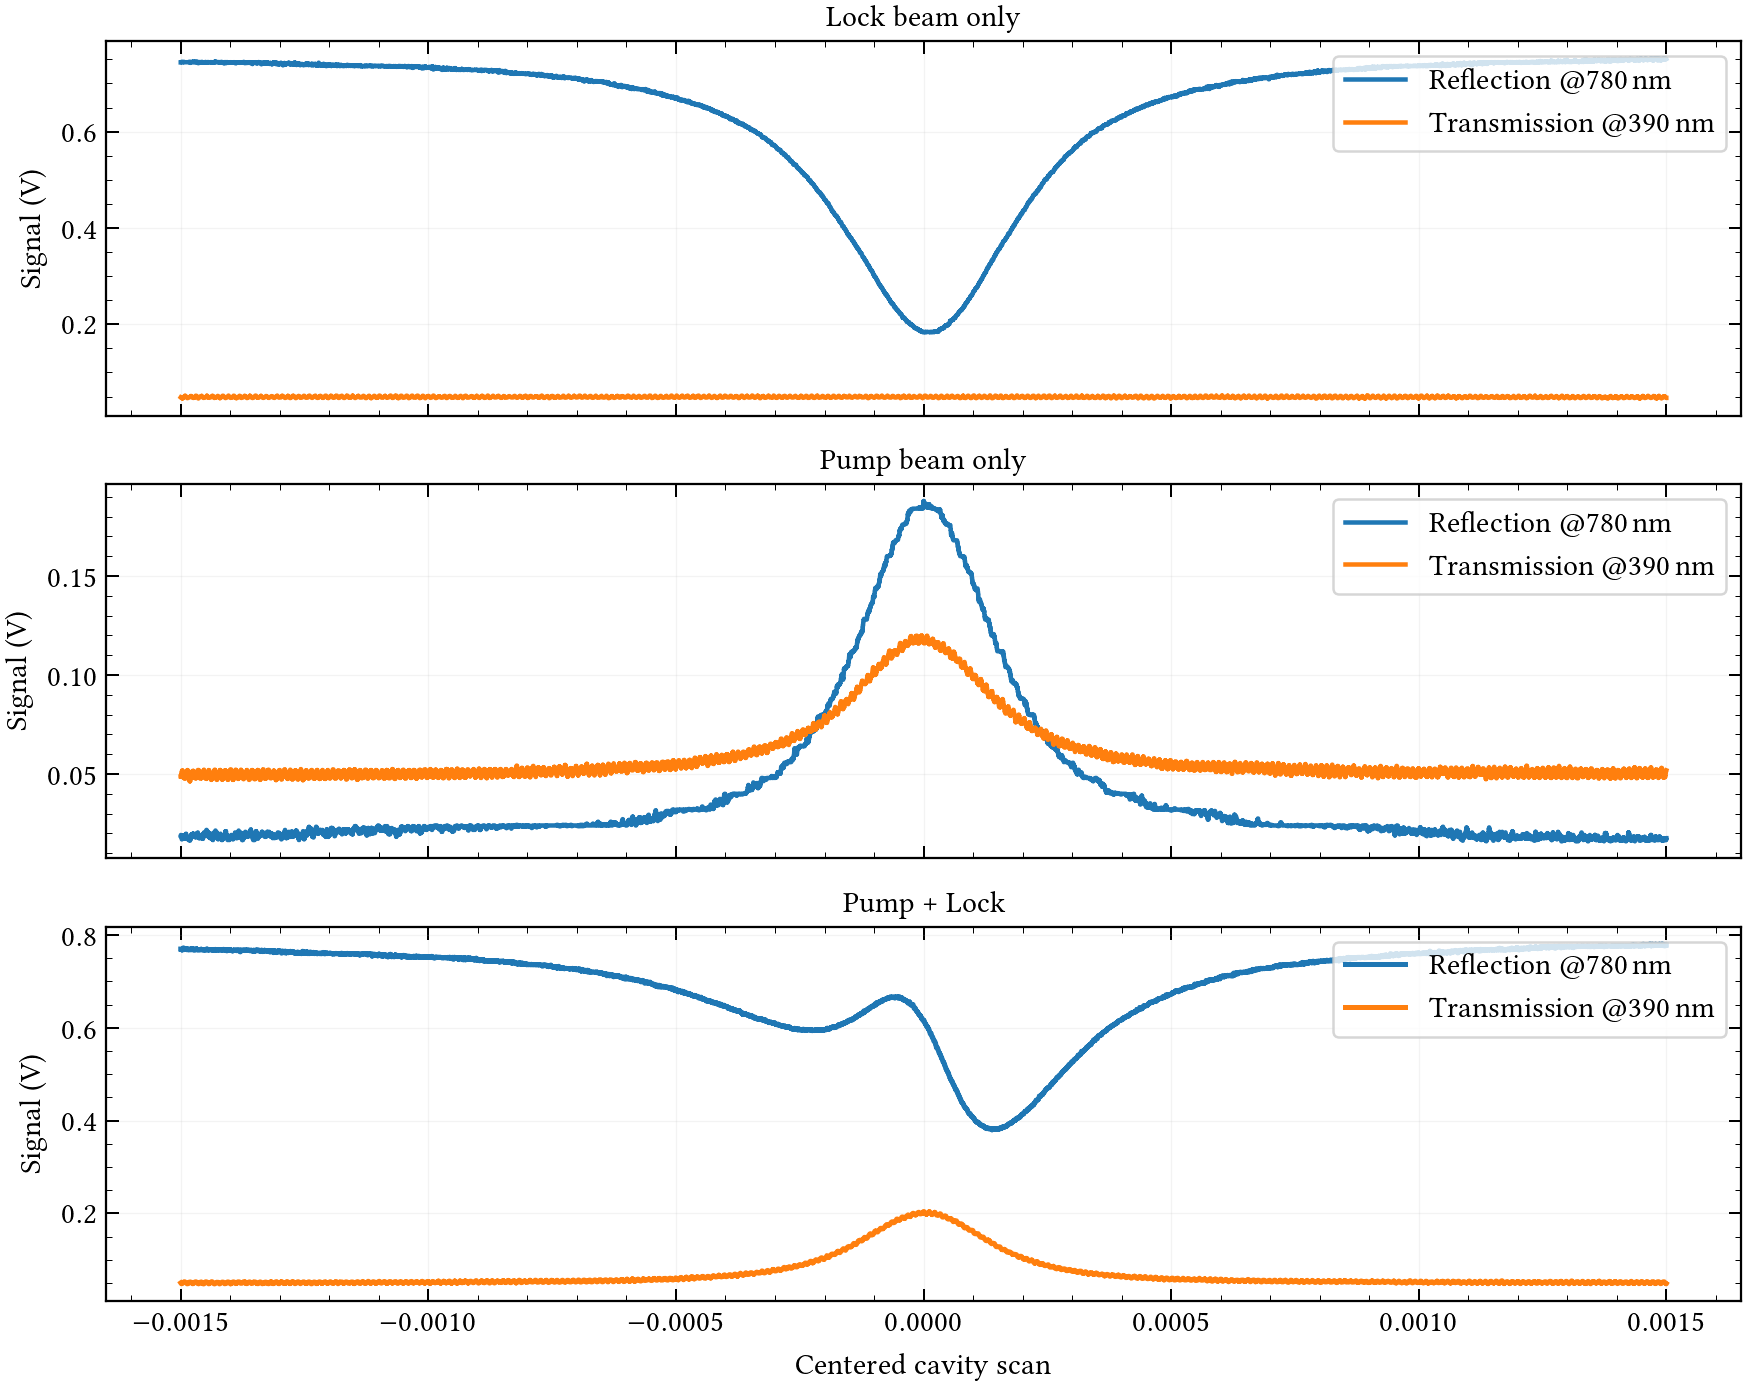

In [11]:
# --- Simple comparison: lock only, pump only, and Pump+Lock ---

# files
name_lock = name2
name_pump = name3
name_both = name1

window_s = 3e-3
half_window = window_s / 2


# -------------------------
# load lock only
# -------------------------

aqm.analysis_cell(filename=os.path.join(path_folder_data, name_exp, name_lock))
data_lock = aqm.data

x_lock = np.array(data_lock["CH1_x"])  # time axis for lock only
r_lock = smooth(np.array(data_lock["CH1_y"]), smooth_N)  # smooth reflection to get better estimate of center
shg_lock = smooth(np.array(data_lock["CH3_y"]), smooth_N)  # smooth SHG to get better estimate of center

t0_lock = x_lock[np.argmin(r_lock)]

x_lock = x_lock - t0_lock


# -------------------------
# load pump only
# -------------------------

aqm.analysis_cell(filename=os.path.join(path_folder_data, name_exp, name_pump))
data_pump = aqm.data

x_pump = np.array(data_pump["CH1_x"])
r_pump = smooth(np.array(data_pump["CH1_y"]), smooth_N)
shg_pump = smooth(np.array(data_pump["CH3_y"]), smooth_N)

t0_pump = x_pump[np.argmax(r_pump)]

x_pump = x_pump - t0_pump


# -------------------------
# load pump + lock
# -------------------------

aqm.analysis_cell(filename=os.path.join(path_folder_data, name_exp, name_both))
data_both = aqm.data

x_both = np.array(data_both["CH1_x"])
r_both = smooth(np.array(data_both["CH1_y"]), smooth_N)
shg_both = smooth(np.array(data_both["CH3_y"]), smooth_N)

# center on SHG peak
t0_both = x_both[np.argmax(shg_both)]

x_both = x_both - t0_both


# -------------------------
# crop same window
# -------------------------

mask_lock = np.abs(x_lock) < half_window
mask_pump = np.abs(x_pump) < half_window
mask_both = np.abs(x_both) < half_window

x_lock_plot = x_lock[mask_lock]
r_lock_plot = r_lock[mask_lock]
shg_lock_plot = shg_lock[mask_lock]
print(f"Lock only: {len(x_lock_plot)} points")

x_pump_plot = x_pump[mask_pump]
r_pump_plot = r_pump[mask_pump]
shg_pump_plot = shg_pump[mask_pump]
print(f"Pump only: {len(x_pump_plot)} points")

x_both_plot = x_both[mask_both]
r_both_plot = r_both[mask_both]
shg_both_plot = shg_both[mask_both]
print(f"Pump + Lock: {len(x_both_plot)} points")

# -------------------------
# numerical sum of reflection features
# -------------------------

# try small shifts by hand
pump_shift = -0.45e-3   # seconds, adjust by eye

r_lock_interp = np.interp(x_both_plot, x_lock_plot, r_lock_plot)
r_pump_interp = np.interp(x_both_plot, x_pump_plot + pump_shift, r_pump_plot)

n_edge = 100

r_lock_base = np.mean(np.r_[r_lock_plot[:n_edge], r_lock_plot[-n_edge:]])
r_pump_base = np.mean(np.r_[r_pump_plot[:n_edge], r_pump_plot[-n_edge:]])
r_both_base = np.mean(np.r_[r_both_plot[:n_edge], r_both_plot[-n_edge:]])

r_sum = r_both_base + (r_lock - r_lock_base) + (r_pump - r_pump_base)

# -------------------------
# plot
# -------------------------

set_plot_style()

fig, axs = plt.subplots(
    3, 1,
    figsize=(10, 8),
    sharex=True
)

# lock only
axs[0].plot(x_lock_plot, r_lock_plot, label=r"Reflection $@780\,\mathrm{nm}$")
axs[0].plot(x_lock_plot, shg_lock_plot, label=r"Transmission $@390\,\mathrm{nm}$")
axs[0].set_title("Lock beam only")
axs[0].set_ylabel("Signal (V)")
axs[0].grid()
axs[0].legend(loc="upper right", frameon=True)

# pump only
axs[1].plot(x_pump_plot, r_pump_plot, label=r"Reflection $@780\,\mathrm{nm}$")
axs[1].plot(x_pump_plot, shg_pump_plot, label=r"Transmission $@390\,\mathrm{nm}$")
axs[1].set_title("Pump beam only")
axs[1].set_ylabel("Signal (V)")
axs[1].grid()
axs[1].legend(loc="upper right", frameon=True)

# pump + lock comparison
axs[2].plot(
    x_both_plot,
    r_both_plot,
    linewidth=2,
    label=r"Reflection $@780\,\mathrm{nm}$"
)

axs[2].plot(
    x_both_plot,
    shg_both_plot,
    linewidth=2,
    label=r"Transmission $@390\,\mathrm{nm}$"
)

# axs[2].plot(
#     x_both_plot,
#     r_sum,
#     "--",
#     color="lightcoral",
#     linewidth=2,
#     label="Lock only + Pump only reflection"
# )

axs[2].set_title("Pump + Lock")
axs[2].set_ylabel("Signal (V)")
axs[2].set_xlabel("Centered cavity scan")
axs[2].grid()
axs[2].legend(loc="upper right", frameon=True)

plt.tight_layout()
plt.show()

# Finesse measurements from resonances

### Load data

**SHG**

In [8]:
L_cav = 490e-3          # m, cavity length
FSR = c / L_cav         # Hz

In [9]:
# 20 mm "Luke"
# 16/06/2026
# path_folder_data = r"./data/oscilloscope/oscilloscope_trace/2026-06-16_shg_cavity_lock_svenska20_luke_002"
# name = "2026_06_16__08_16_12__oscilloscope_trace_shg_cavity_lock_svenska20_luke.h5"

path_folder_data = r"./data/oscilloscope/oscilloscope_trace/2026-10-02_shg_cavity_luke_001"
name = "2026_10_02__13_28_37__oscilloscope_trace_shg_cavity_luke.h5"

folder_data_files = os.listdir(path_folder_data)
print(folder_data_files)
# fine data scan :
# name_exp = 'oscilloscope_trace'
# name_exp = 'oscilloscope_trace_shg_cavity'
name_exp = 'oscilloscope_trace_shg_cavity_luke'

full_path = os.path.join(path_folder_data, name_exp, name)
aqm = AcquisitionAnalysisManager( os.path.join(path_folder_data, name_exp))
aqm.analysis_cell(filename=full_path)

data = aqm.data
print(data)

['oscilloscope_trace_shg_cavity_luke', 'temp.json']


INFO:2026_10_02__13_28_37__oscilloscope_trace_shg_cavity_luke


AnalysisData (rw) (not saved): 
 {
    "CH1_pt_off" (r): "0.000e+00 (type : float64)",
    "CH1_x" (r): "shape: (125000,) (type: ndarray)",
    "CH1_xincr" (r): "8.000e-07 (type : float64)",
    "CH1_xzero" (r): "-5.000e-02 (type : float64)",
    "CH1_y" (r): "shape: (125000,) (type: ndarray)",
    "CH1_y_raw" (r): "shape: (125000,) (type: ndarray)",
    "CH1_ymult" (r): "4.000e-02 (type : float64)",
    "CH1_yoff" (r): "-44.000 (type : float64)",
    "CH1_yzero" (r): "0.000e+00 (type : float64)",
    "CH2_pt_off" (r): "0.000e+00 (type : float64)",
    "CH2_x" (r): "shape: (125000,) (type: ndarray)",
    "CH2_xincr" (r): "8.000e-07 (type : float64)",
    "CH2_xzero" (r): "-5.000e-02 (type : float64)",
    "CH2_y" (r): "shape: (125000,) (type: ndarray)",
    "CH2_y_raw" (r): "shape: (125000,) (type: ndarray)",
    "CH2_ymult" (r): "8.000e-02 (type : float64)",
    "CH2_yoff" (r): "-97.000 (type : float64)",
    "CH2_yzero" (r): "0.000e+00 (type : float64)",
    "CH3_pt_off" (r): "0.000e

### Set signals variables

**SHG**

In [10]:
# time = np.array(data["CH1_x"])

# lock = np.array(data["CH1_y"])   # CH1: lock beam
# ramp = np.array(data["CH2_y"])   # CH2: ramp
# pump = np.array(data["CH3_y"])   # CH3: pump
# shg = np.array(data["CH4_y"])    # CH4: SHG

time = np.array(data["CH1_x"])
lock = np.array(data["CH3_y"])   # CH3: lock beam (pump)
ramp = np.array(data["CH1_y"])   # CH1: ramp

In [11]:
signal = -lock        # change to -pump if you want pump peaks instead
signal = smooth(signal, smooth_N)  # smooth signal to get better estimate of peak centers
# signal = -pump
signal = signal - np.mean(signal)
ramp = ramp - np.mean(ramp)

ramp_norm = ramp / np.max(np.abs(ramp))
# Smooth norm signal
smooth_ramp = smooth(ramp_norm, smooth_N)


In [12]:
print("global max:", signal.max(), "at index", np.argmax(signal))

global max: 6.767875199999999 at index 70300


### Find the linear part of the ramp

In [13]:
max_ramp = np.max(ramp)
min_ramp = np.min(ramp)

percent_low_bound = 0.05
percent_high_bound = 0.15
threshold_low = min_ramp + percent_low_bound * (max_ramp - min_ramp)
threshold_high = max_ramp - percent_high_bound * (max_ramp - min_ramp)
linear_mask = (ramp > threshold_low) & (ramp < threshold_high)

ramp_direction = "negative"  # "positive" or "negative"

segments = []
min_segment_length = 1000
in_segment = False

for i, val in enumerate(linear_mask):
    if val and not in_segment:
        start_idx = i
        in_segment = True
    elif (not val or i == len(linear_mask)-1) and in_segment:
        end_idx = i
        in_segment = False
        if end_idx - start_idx >= min_segment_length:
            slope = np.polyfit(np.arange(end_idx - start_idx), ramp[start_idx:end_idx], 1)[0]
            if (ramp_direction == "positive" and slope > 0) or (ramp_direction == "negative" and slope < 0):
                segments.append((start_idx, end_idx))

print(f"Found {len(segments)} {ramp_direction} linear segments.")

Found 2 negative linear segments.


### Plot raw data with peaks and ramp segment highlighted

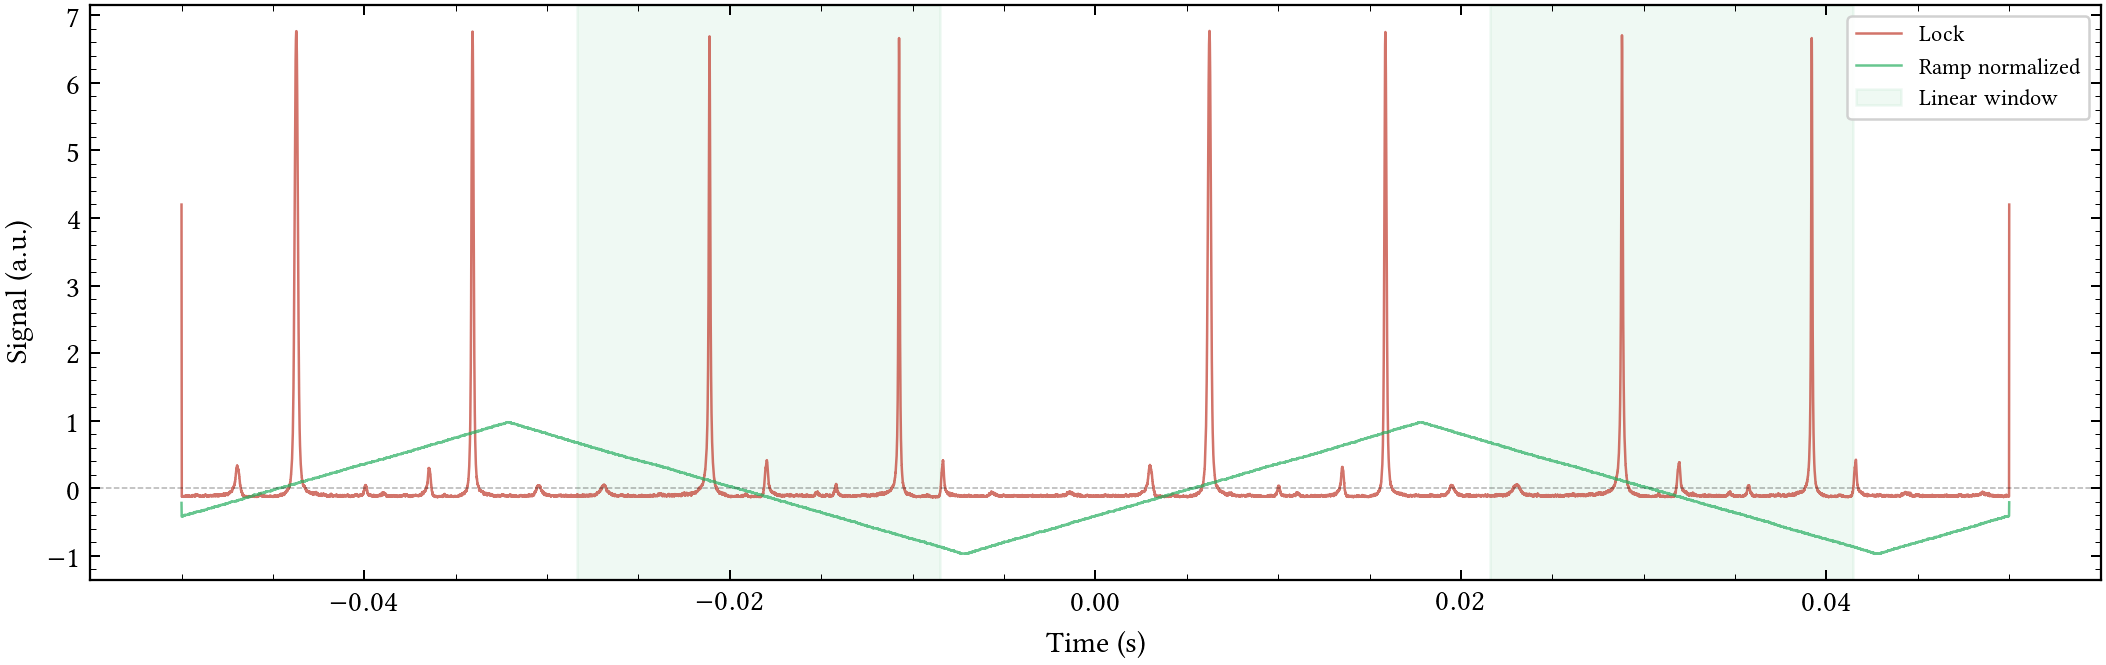

In [14]:
fig, ax = plt.subplots(figsize=(12, 4))

# ax.plot(time, pump,        color="#C0392B", linewidth=1.2, label="Pump")
# ax.plot(time, shg,        color="#2E86AB", linewidth=1.2, label="SHG")
ax.plot(time, signal,        color="#C0392B", linewidth=1.0, alpha=0.7, label="Lock")
ax.plot(time, smooth_ramp, color="#27AE60", linewidth=1.0, alpha=0.7, label="Ramp normalized")

for i, (start_idx, end_idx) in enumerate(segments):
    ax.axvspan(time[start_idx], time[end_idx],
               color="#27AE60", alpha=0.07,
               label="Linear window" if i == 0 else None)

ax.axhline(0, color="black", linewidth=0.6, linestyle="--", alpha=0.3)
ax.tick_params(direction="in", top=True, right=True, length=4, width=0.8)
ax.set_xlabel("Time (s)")
ax.set_ylabel("Signal (a.u.)")
ax.legend(frameon=True, framealpha=0.9, edgecolor="0.8", fontsize=9)
fig.tight_layout()

### Find peaks and fit Lorentzian

In [15]:
peak_fits = []
all_peaks = []

height = 6.0  # minimum height of peaks, adjust as needed
prominence = 0.04  # minimum prominence of peaks, adjust as needed
N = 1000  # number of points to take around each peak for fitting, adjust as needed

# first pass: find all peaks
for window_id, (start_idx, end_idx) in enumerate(segments):

    segment_signal = signal[start_idx:end_idx]
    print(window_id, start_idx, end_idx, segment_signal.min(), segment_signal.max())
    peaks, props = find_peaks(
        segment_signal,
        height=height,
        prominence=prominence,
        distance=100  # Minimum distance between peaks
    )

    print(f"Window {window_id}: {len(peaks)} peaks")
    print(np.allclose(segment_signal[peaks],
                  props["peak_heights"]))

    print(segment_signal[peaks])
    print(props["peak_heights"])

    for peak in peaks:
        all_peaks.append((start_idx + peak, window_id))

    

print(f"Total peaks found: {len(all_peaks)}")

# calibration from all detected peaks
peak_times = np.array([time[idx] for idx, window_id in all_peaks])
peak_times = np.sort(peak_times)

time_per_FSR = np.median(np.diff(peak_times))
Hz_per_sec = FSR / time_per_FSR

print(f"time_per_FSR = {time_per_FSR:.3e} s")
print(f"Hz_per_sec   = {Hz_per_sec:.3e} Hz/s")

# second pass: fit all peaks
for idx, window_id in all_peaks:

    if idx - N < 0 or idx + N >= len(signal):
        continue

    xdata = time[idx-N:idx+N]
    ydata = signal[idx-N:idx+N]

    C_guess = np.median(ydata)          # robust baseline estimate
    A_guess = ydata[np.argmin(np.abs(xdata - time[idx]))] - C_guess
    x0_guess = time[idx]

    # estimate width directly from the data around the peak
    half_max = C_guess + A_guess / 2
    above = np.where(ydata > half_max)[0] if A_guess > 0 else np.where(ydata < half_max)[0]
    if len(above) > 1:
        gamma_guess = xdata[above[-1]] - xdata[above[0]]
    else:
        gamma_guess = 20 * (time[1] - time[0])

    p0 = [A_guess, x0_guess, gamma_guess, C_guess]
    bounds = (
        [-np.inf, xdata[0], 0, -np.inf],
        [np.inf, xdata[-1], (xdata[-1] - xdata[0]), np.inf]
    )
    popt, pcov = curve_fit(lorentzian, xdata, ydata, p0=p0, bounds=bounds, maxfev=5000)

    A_fit, x0_fit, gamma_fit, C_fit = popt

    gamma_freq = abs(gamma_fit * Hz_per_sec)
    finesse = FSR / gamma_freq

    peak_fits.append({
        "A": A_fit,
        "x0": x0_fit,
        "gamma_time": gamma_fit,
        "gamma_freq": gamma_freq,
        "finesse": finesse,
        "C": C_fit,
        "window_id": window_id,
        "time_per_FSR": time_per_FSR,
        "xdata": xdata,     # <-- add this
        "ydata": ydata,      # <-- add this
    })

    # print(window_id,
    #   idx,
    #   signal[idx],
    #   np.max(signal[idx-N:idx+N]))
    
print(f"Fitted {len(peak_fits)} peaks")


0 27038 51898 -0.1377247999999991 6.687875199999999
Window 0: 2 peaks
True
[6.6878752 6.6622752]
[6.6878752 6.6622752]
1 89501 114313 -0.1313247999999998 6.703875199999999
Window 1: 2 peaks
True
[6.7038752 6.6622752]
[6.7038752 6.6622752]
Total peaks found: 4
time_per_FSR = 1.038e-02 s
Hz_per_sec   = 5.893e+10 Hz/s
Fitted 4 peaks


### Plot fitted curves

Fitted 4 peaks across 2 windows.


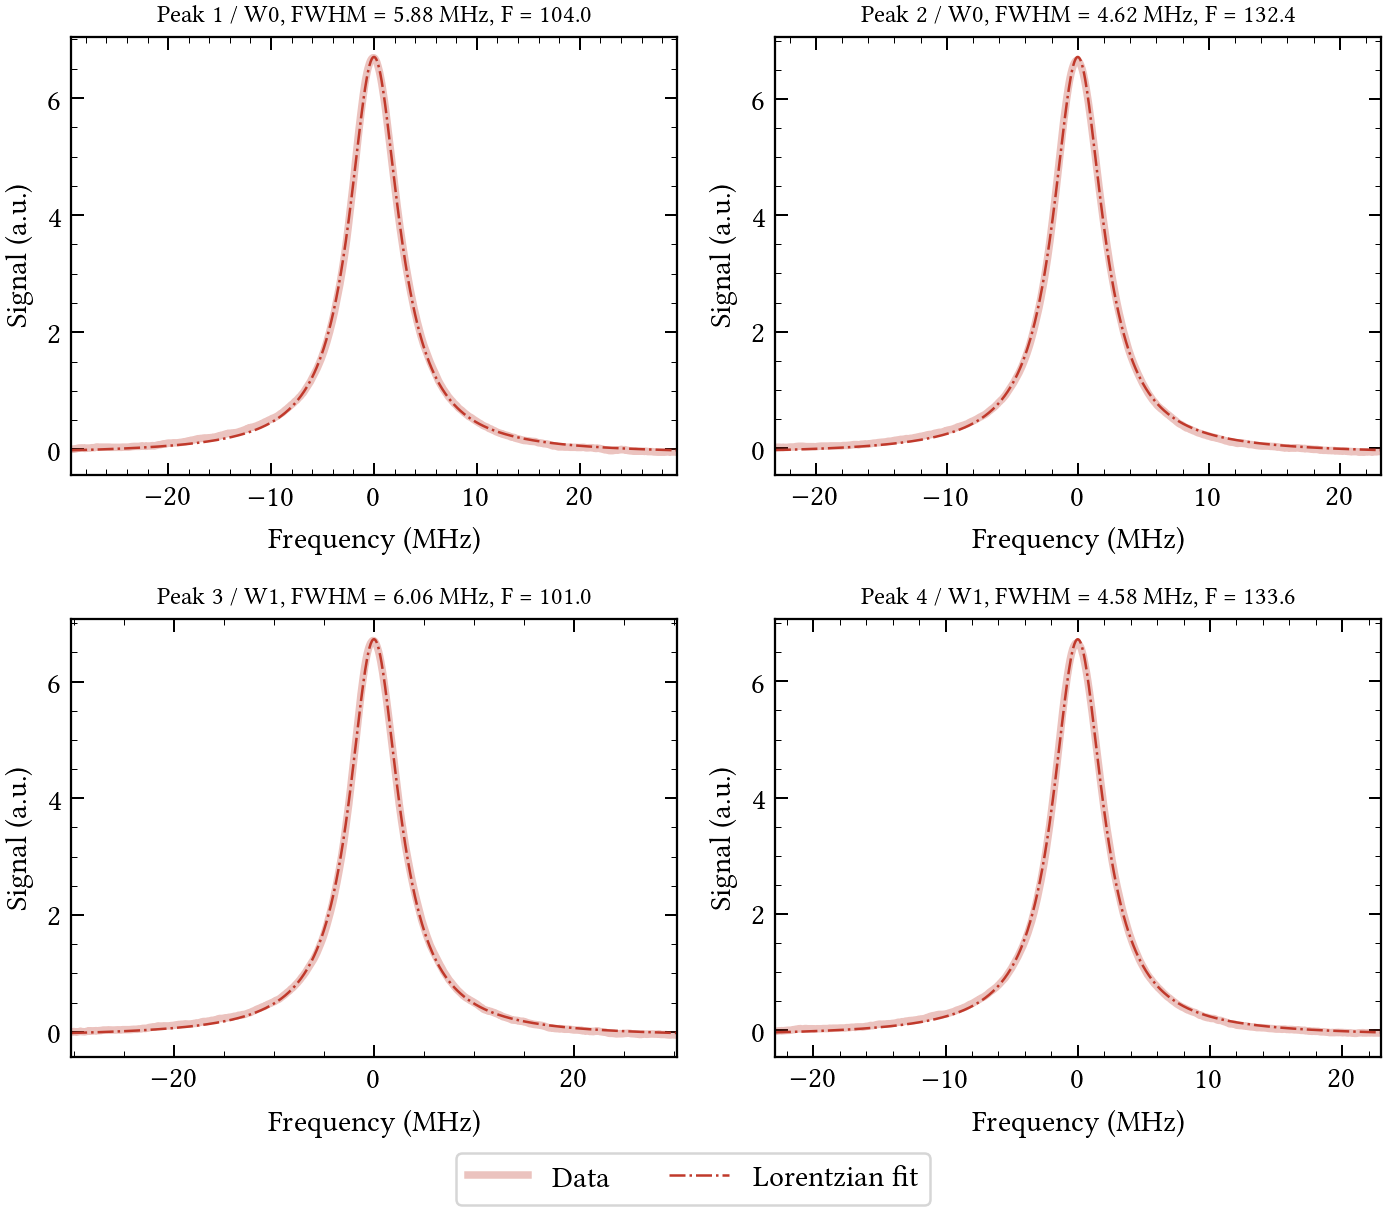

In [16]:
num_peaks = len(peak_fits)
print(f"Fitted {num_peaks} peaks across {len(segments)} windows.")

cols = int(np.ceil(np.sqrt(num_peaks)))
rows = int(np.ceil(num_peaks / cols))

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(4*cols, 3.5*rows)
)

axes = np.array(axes).reshape(-1)

for i, pf in enumerate(peak_fits):

    ax = axes[i]

    A = pf["A"]
    x0 = pf["x0"]
    gamma_time = pf["gamma_time"]
    gamma_freq = pf["gamma_freq"]
    finesse = pf["finesse"]
    C = pf["C"]

    time_per_FSR = pf["time_per_FSR"]
    Hz_per_sec = FSR / time_per_FSR

    t_fit = np.linspace(
        x0 - 5*abs(gamma_time),
        x0 + 5*abs(gamma_time),
        1000
    )

    y_fit = lorentzian(t_fit, A, x0, gamma_time, C)

    freq_fit = (t_fit - x0) * Hz_per_sec / 1e6
    freq_data = (pf["xdata"] - x0) * Hz_per_sec / 1e6

    ax.plot(freq_data, pf["ydata"], color="#C0392B", alpha=0.3, lw=3.0, label="Data")
    ax.plot(freq_fit, y_fit, color="#C0392B", linestyle="-.", lw=1.0, label="Lorentzian fit")

    ax.set_xlim(freq_fit[0], freq_fit[-1])

    ax.set_title(
        f"Peak {i+1} / W{pf['window_id']}, "
        f"FWHM = {gamma_freq/1e6:.2f} MHz, "
        f"F = {finesse:.1f}",
        fontsize=10
    )

    ax.set_xlabel("Frequency (MHz)")
    ax.set_ylabel("Signal (a.u.)")

# hide unused axes
for j in range(i+1, len(axes)):
    axes[j].axis("off")

# common legend
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    frameon=True,
    bbox_to_anchor=(0.5, 0.01)
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
# plt.savefig("./plot/figure/"+"finesse_luke.svg", dpi=300)
plt.show()

In [39]:
HR = 0.9998
TR = 1 - HR
sum = 3*TR + 0.05
f = 2*np.pi / sum
print(f)

124.17362267153348


### Summary

In [40]:
for i, pf in enumerate(peak_fits):
    print(
        f"Peak {i+1}: "
        f"FWHM = {pf['gamma_freq']/1e6:.3f} MHz, "
        f"Finesse = {pf['finesse']:.1f}"
    )

# Average FWHM and Finesse
gamma_freqs = np.array([pf["gamma_freq"] for pf in peak_fits])
finesses = np.array([pf["finesse"] for pf in peak_fits])
print(f"Average FWHM = {np.mean(gamma_freqs)/1e6:.3f} MHz")
print(f"Average Finesse = {np.mean(finesses):.1f}")

Peak 1: FWHM = 4.882 MHz, Finesse = 125.3
Peak 2: FWHM = 10.872 MHz, Finesse = 56.3
Peak 3: FWHM = 4.950 MHz, Finesse = 123.6
Peak 4: FWHM = 7.029 MHz, Finesse = 87.0
Peak 5: FWHM = 4.920 MHz, Finesse = 124.4
Peak 6: FWHM = 10.454 MHz, Finesse = 58.5
Peak 7: FWHM = 5.037 MHz, Finesse = 121.5
Peak 8: FWHM = 6.724 MHz, Finesse = 91.0
Average FWHM = 6.858 MHz
Average Finesse = 98.4
